# Potencial de estrago sísmico nacional

## Cenário
Terremotos de mesma magnitude têm consequências muito diferentes conforme onde ocorrem: um abalo forte numa região pouco habitada pode não deixar vítimas, enquanto outro, numa área densa e com construções vulneráveis, pode matar milhares de pessoas.

**Problema:** construir um indicador de potencial de estrago por país, dado que um terremoto de magnitude *X* o atinge.

**Hipótese:** o potencial cresce com a exposição (densidade populacional) e diminui com a capacidade de resistência (PIB per capita, usado como proxy da qualidade das construções e da resposta a emergências).

| Densidade | PIB per capita | Potencial esperado |
|---|---|---|
| baixa | qualquer | baixo |
| alta | alto | intermediário |
| alta | baixo | alto |

**Usuários:** defesa civil, seguradoras e resseguradoras, organizações humanitárias.
**Custo dos erros:** subestimar o potencial de um país (falso negativo) é pior que superestimar, pois eventos graves são raros e deixam o país despreparado.

## Dataset
**Fontes:** USGS (terremotos M ≥ 5,5, 1990–2023), NOAA/NCEI (mortes), Banco Mundial (PIB per capita e densidade populacional por país e ano), Natural Earth (fronteiras, para atribuir cada epicentro a um país) e Taiwan (PIB e densidade inseridos manualmente, pois não consta no Banco Mundial).

**Construção:** o USGS é o universo de eventos e o NOAA preenche as mortes (sem registro = 0). Réplicas foram removidas por declustering e suas mortes somadas ao evento principal. As 800 mortes de 15/06/1991 nas Filipinas (erupção do Pinatubo) foram retiradas do terremoto. Séries do Banco Mundial com lacunas foram interpoladas e preenchidas nas pontas (colunas `*_imputado`).

**Dois datasets, derivados da mesma base:**

| Dataset | Unidade | Tamanho | Uso |
|---|---|---|---|
| `events_modelo.csv` | terremoto (mainshock M ≥ 6) | 3.243 eventos, 92 países | classificação |
| `countries_cluster.csv` | país com pelo menos um M ≥ 6 | 93 países | clustering |

## Variáveis
- **Alvo (classificação):** `alta_mortalidade` = 1 se o evento causou ≥ 100 mortes (91 eventos, 2,8%).
- **Features:** `mag`, `prof_km`, `dist_costa_km`, `log_pib_pc`, `log_dens_pop`, `grupo_renda`.
- **Clustering:** `log(taxa_anual)` de M ≥ 6, `log1p(mortes_medias_evento)`, `log_pib_pc`, `log_dens_pop` (padronizadas).
- **Proibidas como feature (vazamento):** `mortes`, `log_mortes`, `mortes_min`, `mortes_max`, `dano_total_musd`.

## Limitações
- Densidade nacional média é um proxy fraco de exposição (o que importa é a população perto do epicentro).
- PIB per capita não mede a qualidade das construções.
- Mortes são atribuídas ao país do epicentro, mesmo quando o evento mata em vários países (Sumatra 2004).
- Evento sem registro no NOAA foi tratado como 0 mortes.
- Apenas 91 positivos, então as métricas são instáveis e a validação deve ser feita por país.
- Alguns valores do Banco Mundial foram preenchidos por imputação (por exemplo, o Afeganistão antes de 2002).


In [ ]:
%pip install numpy pandas matplotlib seaborn scikit-learn geopandas shapely ipykernel

In [7]:
import numpy
import pandas
import geopandas
import sklearn

print("Ambiente configurado!")

Ambiente configurado!


In [1]:
# Executar o wrangling

import wrangling_sismos

ev, paises_completos, eventos, paises = wrangling_sismos.main()

print("Wrangling concluído!")
print("Eventos:", eventos.shape)
print("Países:", paises.shape)

[USGS] arquivo cobre 1990-01-02 01:25:06.560000 -> 2024-01-01 09:08:17.603000 (16863 eventos)
  eventos/ano (min / mediana / max): 387 / 484 / 714
[GEO] 3317 eventos em terra; 13540 no mar (buscando país mais próximo; pode demorar)
  atribuídos a país: 9998 | mar aberto (descartáveis): 3542
[DECLUSTER] 12849 mainshocks | 4008 réplicas/precursores (até 30 dias após o evento maior, raio >= 100 km, crescente com a magnitude)
[NOAA] 1710 eventos em 1990-2023 | com mortes>0: 746 | mortes assumidas 0: 963
[MATCH] NOAA casados com USGS: 1202/1710 (70%)
  NOAA com mortes e SEM match: 161 (salvo em noaa_sem_match.csv). Maiores:
  Year  Mo   Dy                                  local     lat     lon  mag_noaa  mortes_max
2002.0 1.0 17.0                       RWANDA:  GISENYI  -1.684  29.077       4.7      1001.0
1991.0 7.0 23.0            PERU:  MACA, CHIVAY, YANQUE -15.679 -71.574       4.7        92.0
2002.0 4.0 12.0 TAJIKISTAN; AFGHANISTAN: DO ABI-NAHRIN  39.959  69.417       5.9        50.0
1

In [10]:
cols = ["mag", "prof_km", "iso3", "mortes", "alta_mortalidade", "log_mortes", "log_pib_pc", "log_dens_pop"]
print(eventos[cols].describe(include="all").T)
print()
print(eventos["alta_mortalidade"].value_counts(dropna=False))
paises.head()

                   count unique  top freq        mean          std       min  \
mag               3407.0    NaN  NaN  NaN    6.414875      0.44676       6.0   
prof_km           3407.0    NaN  NaN  NaN   87.263646   143.599276    -0.097   
iso3                3407     92  IDN  533         NaN          NaN       NaN   
mortes            3407.0    NaN  NaN  NaN  290.492222  7110.632904       0.0   
alta_mortalidade  3407.0    NaN  NaN  NaN    0.027003     0.162117       0.0   
log_mortes        3407.0    NaN  NaN  NaN    0.364436     1.286241       0.0   
log_pib_pc        3407.0    NaN  NaN  NaN    8.301519     1.388046  3.936538   
log_dens_pop      3407.0    NaN  NaN  NaN    3.947913     1.217493 -1.986151   

                       25%       50%      75%        max  
mag                    6.1       6.3      6.6        9.1  
prof_km              14.95      33.0     76.7      687.6  
iso3                   NaN       NaN      NaN        NaN  
mortes                 0.0       0.0      0

,iso3,pais,regiao,grupo_renda,pib_pc,dens_pop,n_eventos_bruto,mortes_totais,n_alta_mortalidade,n_eventos,anos_com_evento,mag_max,mortes_medias_evento,taxa_anual,prob_anual_poisson,prob_anual_empirica,tem_evento,log_pib_pc,log_dens_pop
1,AFG,Afghanistan,Middle East & North Africa,Low income,424.092446,62.259829,52.0,9960.0,8.0,47.0,23.0,7.5,211.914894,1.382353,0.749013,0.676471,True,6.049951,4.131316
3,ALB,Albania,Europe & Central Asia,Upper middle income,8744.232621,89.695480,1.0,51.0,0.0,1.0,1.0,6.4,51.000000,0.029412,0.028983,0.029412,True,9.076150,4.496420
6,ARG,Argentina,Latin America & Caribbean,Upper middle income,12331.642903,16.590236,58.0,3.0,0.0,54.0,26.0,7.3,0.055556,1.588235,0.795714,0.764706,True,9.419924,2.808814
8,ASM,American Samoa,East Asia & Pacific,High income,16383.055836,242.354856,1.0,0.0,0.0,1.0,1.0,6.2,0.000000,0.029412,0.028983,0.029412,True,9.704003,5.490403
9,ATG,Antigua and Barbuda,Latin America & Caribbean,High income,20215.616168,210.736659,1.0,0.0,0.0,1.0,1.0,6.0,0.000000,0.029412,0.028983,0.029412,True,9.914211,5.350609


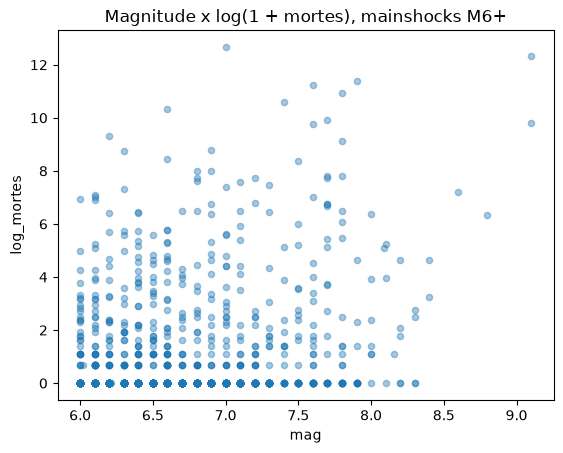

In [11]:
import matplotlib.pyplot as plt

ax = eventos.plot.scatter(x="mag", y="log_mortes", alpha=0.4)
ax.set_title("Magnitude x log(1 + mortes), mainshocks M6+")
plt.show()

## Clusterização de países

**O que é.** Clusterização é um método não supervisionado: o algoritmo agrupa os países por semelhança, sem que a gente diga quais grupos existem. Cada país é descrito por quatro variáveis (em escala log e padronizadas):

| Variável | O que representa |
|---|---|
| `log_taxa_anual` | frequência de terremotos M6+ |
| `log_mortes_medias` | letalidade média desses terremotos |
| `log_pib_pc` | riqueza (capacidade de resistir) |
| `log_dens_pop` | exposição |

**Etapas:**
1. Padronizar as variáveis, para que nenhuma domine pela escala.
2. Escolher o número de clusters *k* (silhouette e cotovelo da inércia).
3. Rodar o K-Means.
4. Ordenar os clusters do menor ao maior potencial de estrago. Essa ordem é o indicador.
5. Visualizar (PCA), validar com casos conhecidos e testar robustez.

**Ordenação:** o `score_estrago` de cada cluster é a média de três coordenadas do seu centro: letalidade média + densidade − PIB per capita. É a hipótese do projeto escrita como conta. A frequência de terremotos fica de fora do score porque o indicador pergunta o que acontece *se* um terremoto atingir o país.

**Interpretação:** *(escreva com suas palavras o que caracteriza cada nível, quais países surpreendem e por quê.)*

93 países | faltantes: 0


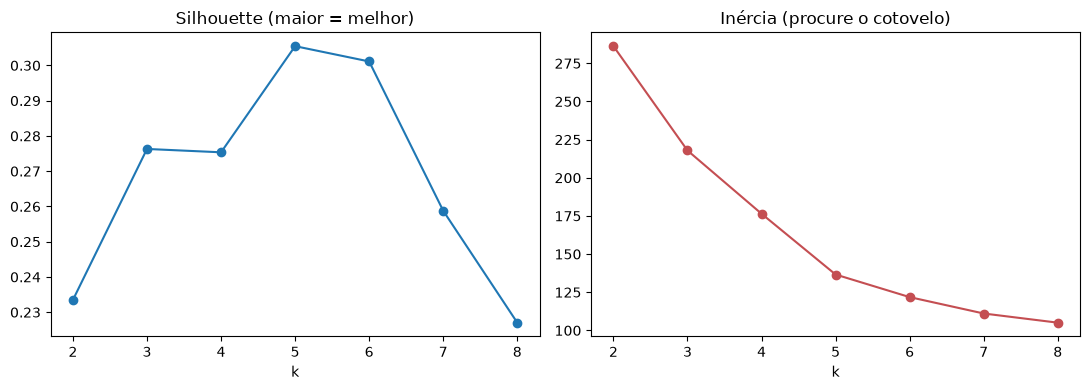

,paises,taxa_anual,mortes_medias,pib_pc,dens_pop
nivel_estrago,,,,,
1,10,0.12,0.00,42528.09,4.38
2,23,0.03,1.00,18138.35,126.30
3,26,1.41,5.25,8445.83,53.02
4,22,0.06,3.00,1848.00,58.38
5,12,0.46,1285.87,4096.77,148.91


Nível 1: KAZ, SAU, CAN, AUS, BWA, GRL, ISL, MNG, NCL, NOR
Nível 2: ITA, ALB, AZE, MYS, ROU, PRT, HRV, PRI, DOM, CYP, DMA, FRA
Nível 3: JPN, PHL, TWN, RUS, PNG, COL, PER, ECU, MEX, CHL, GRC, WSM
Nível 4: GEO, MMR, KGZ, VEN, SSD, BTN, TKM, COD, UGA, HND, TZA, MOZ
Nível 5: HTI, IDN, CHN, PAK, TUR, IRN, IND, AFG, NPL, MAR, DZA, SLV


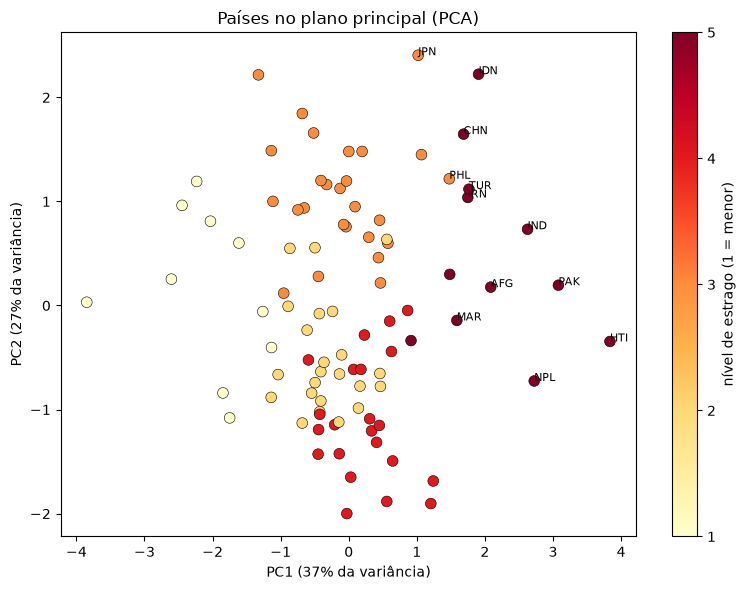

,iso3,pais,nivel_estrago,n_eventos,mortes_medias_evento,pib_pc,dens_pop
15,CHN,China,5,65.0,1423.7,12419.2,150.2
39,HTI,Haiti,5,2.0,159124.0,1807.4,416.8
83,TUR,Türkiye,5,18.0,4254.7,12420.0,109.8
40,IDN,Indonesia,5,508.0,486.1,4548.6,147.6
60,NPL,Nepal,5,2.0,4537.0,1339.2,204.9
14,CHL,Chile,3,131.0,4.7,15852.2,26.3
50,MEX,Mexico,3,114.0,5.8,11805.5,66.2
45,JPN,Japan,3,226.0,113.0,37802.3,343.4
61,NZL,New Zealand,3,43.0,4.4,47470.9,19.5
87,USA,United States,3,177.0,0.4,76846.6,36.6


Silhouette (k=5): 0.305
Estabilidade entre sementes (ARI médio): 1.000
Concordância K-Means x hierárquico (ARI): 0.499


,iso3,pais,grupo_renda,cluster,nivel_estrago,n_eventos,taxa_anual,mortes_medias_evento,pib_pc,dens_pop
39,HTI,Haiti,Lower middle income,2,5,2.0,0.06,159124.00,1807.43,416.80
62,PAK,Pakistan,Lower middle income,2,5,12.0,0.35,6447.83,1442.60,314.86
60,NPL,Nepal,Lower middle income,2,5,2.0,0.06,4537.00,1339.22,204.86
83,TUR,Türkiye,Upper middle income,2,5,18.0,0.53,4254.72,12420.03,109.78
42,IRN,"Iran, Islamic Rep.",Upper middle income,2,5,34.0,1.00,2236.09,4384.31,55.16
15,CHN,China,Upper middle income,2,5,65.0,1.91,1423.74,12419.24,150.22
25,DZA,Algeria,Upper middle income,2,5,2.0,0.06,1148.00,4929.62,19.04
41,IND,India,Lower middle income,2,5,37.0,1.09,899.24,2313.86,479.10
49,MAR,Morocco,Lower middle income,2,5,4.0,0.12,893.75,3809.23,83.53
40,IDN,Indonesia,Upper middle income,2,5,508.0,14.94,486.15,4548.57,147.61


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# ---------- 1. Dados e parâmetros ----------
BASE = "https://raw.githubusercontent.com/EnzoSottoRib/projeto_sismos/refs/heads/main/saida"
paises = pd.read_csv(f"{BASE}/countries_cluster.csv")

K = 5             # número de clusters (confira nos gráficos da etapa 2)
MIN_EVENTOS = 1   # use 3 para testar sem países com poucos eventos
SEED = 42

base = paises[paises["n_eventos"] >= MIN_EVENTOS].reset_index(drop=True)
X = pd.DataFrame({
    "log_taxa_anual": np.log(base["taxa_anual"]),
    "log_mortes_medias": np.log1p(base["mortes_medias_evento"]),
    "log_pib_pc": base["log_pib_pc"],
    "log_dens_pop": base["log_dens_pop"],
})
Z = StandardScaler().fit_transform(X)   # média 0 e desvio 1
print(f"{len(base)} países | faltantes: {int(X.isna().sum().sum())}")

# ---------- 2. Escolha de k ----------
ks = range(2, 9)
sil, ine = [], []
for k in ks:
    m = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    sil.append(silhouette_score(Z, m.labels_)); ine.append(m.inertia_)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), sil, "o-"); ax[0].set_title("Silhouette (maior = melhor)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), ine, "o-", color="#C44E52"); ax[1].set_title("Inércia (procure o cotovelo)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# ---------- 3. K-Means e ordenação pelo potencial de estrago ----------
km = KMeans(K, n_init=20, random_state=SEED).fit(Z)
base["cluster"] = km.labels_
cent = pd.DataFrame(km.cluster_centers_, columns=X.columns)
cent["score_estrago"] = (cent["log_mortes_medias"] + cent["log_dens_pop"] - cent["log_pib_pc"]) / 3
base["nivel_estrago"] = base["cluster"].map(cent["score_estrago"].rank(method="first").astype(int))  # 1 = menor, K = maior

perfil = base.groupby("nivel_estrago").agg(
    paises=("iso3", "size"), taxa_anual=("taxa_anual", "median"),
    mortes_medias=("mortes_medias_evento", "median"),
    pib_pc=("pib_pc", "median"), dens_pop=("dens_pop", "median")).round(2)
display(perfil)
for n, g in base.groupby("nivel_estrago"):
    print(f"Nível {n}: " + ", ".join(g.sort_values("mortes_totais", ascending=False)["iso3"].head(12)))

# ---------- 4. Visualização em 2D (PCA) ----------
pca = PCA(2, random_state=SEED).fit(Z)
P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(P[:, 0], P[:, 1], c=base["nivel_estrago"], cmap="YlOrRd", s=60, edgecolor="k", linewidth=0.4)
for i in base["mortes_totais"].nlargest(12).index:
    ax.annotate(base.loc[i, "iso3"], (P[i, 0], P[i, 1]), fontsize=8)
plt.colorbar(sc, label="nível de estrago (1 = menor)", ticks=range(1, K + 1))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} da variância)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} da variância)")
ax.set_title("Países no plano principal (PCA)")
plt.tight_layout(); plt.show()

# ---------- 5. Validação e robustez ----------
conhecidos = ["HTI", "NPL", "TUR", "IDN", "CHN", "JPN", "CHL", "NZL", "USA", "MEX"]
display(base[base["iso3"].isin(conhecidos)][["iso3", "pais", "nivel_estrago", "n_eventos", "mortes_medias_evento", "pib_pc", "dens_pop"]]
        .sort_values("nivel_estrago", ascending=False).round(1))
rotulos = [KMeans(K, n_init=20, random_state=s).fit_predict(Z) for s in range(10)]
hier = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
print(f"Silhouette (k={K}): {silhouette_score(Z, base['cluster']):.3f}")
print(f"Estabilidade entre sementes (ARI médio): {np.mean([adjusted_rand_score(rotulos[0], r) for r in rotulos[1:]]):.3f}")
print(f"Concordância K-Means x hierárquico (ARI): {adjusted_rand_score(base['cluster'], hier):.3f}")

# ---------- 6. Indicador por país ----------
indicador = base[["iso3", "pais", "grupo_renda", "cluster", "nivel_estrago", "n_eventos",
                  "taxa_anual", "mortes_medias_evento", "pib_pc", "dens_pop"]].sort_values(
    ["nivel_estrago", "mortes_medias_evento"], ascending=[False, False])
display(indicador.head(15).round(2))
indicador.to_csv("paises_clusters.csv", index=False)

### Conclusões

**Escolha do número de clusters.** Testamos primeiro K = 4, mas o resultado foi pouco assertivo: o silhouette ficou em 0,275, a concordância com o clustering hierárquico foi baixa (ARI = 0,43) e o grupo de maior estrago misturou perfis diferentes, incluindo Japão e Taiwan, que entraram ali por causa de um único evento marcante (Tōhoku e Chi-Chi), apesar de serem ricos e de terem mortalidade média muito abaixo da dos demais países do grupo. Com K = 5 o resultado melhorou: o silhouette subiu para 0,305, a estabilidade entre sementes ficou total (ARI = 1,00), a concordância com o hierárquico subiu para 0,50 e o grupo de maior estrago ficou mais coerente. Por isso adotamos K = 5.

**Perfis encontrados (K = 5), do menor ao maior potencial de estrago.**
- **Nível 1 (10 países):** muito pouco densos (~4 hab/km²) e ricos (PIB per capita de ~US$ 42 mil), como Cazaquistão, Canadá, Austrália e Noruega, praticamente sem mortes: baixa exposição implica baixo potencial.

- **Nível 2 (23 países):** terremotos raros (~0,03 evento M6+ por ano, cerca de um a cada 30 anos), renda média-alta (~US$ 18 mil) e densidade média (~126 hab/km²), como Itália, Portugal, Romênia, França e Chipre. A mortalidade mediana é de ~1 morte por evento.

- **Nível 3 (26 países):** muito sísmicos (~1,4 evento M6+ por ano), com estrago moderado (mortalidade mediana de ~5 mortes por evento), como Japão, Chile, México, EUA e Nova Zelândia.

- **Nível 4 (22 países):** os mais pobres (PIB de ~US$ 1,8 mil), menos densos que os do nível 5 e com terremotos raros, como Mianmar, Venezuela, Geórgia e Uganda; a mortalidade média é ~3 contra ~1.286 no nível 5. Pobreza sozinha não gera mortes: é preciso população exposta e terremotos graves. Representa potencial ainda não realizado.

- **Nível 5 (12 países, maior estrago):** Haiti, Indonésia, China, Paquistão, Turquia, Irã, Índia, Afeganistão e Nepal, com densidade mediana de ~149 hab/km², PIB per capita de ~US$ 4,1 mil e mortalidade mediana de ~1.286 mortes por evento.

**Limitações.** O silhouette é moderado; países com poucos eventos (Haiti, Nepal, Argélia, Sudão do Sul) têm classificação baseada em um único terremoto; o Japão é outlier no nível 3 por causa do Tōhoku; a ordem dos níveis intermediários depende dos pesos do score; e os resultados mostram associação, não causalidade.